# 6. PR Complexity Component Ablation
Run from the repository's **notebooks** directory. Change `INPUT_PATH` below, then **Run All**.
Requires Python 3.10+ with pandas, numpy, scipy, matplotlib, and jinja2.
If needed, run `%pip install pandas numpy scipy matplotlib jinja2` in a separate cell.

This notebook evaluates the realized (post-review) score from notebook #4:
30% code, 20% files, 25% review burden, 10% configuration, and 15% category breadth.
Review burden is 60% review-comment percentile + 40% reviewer percentile.

For each ablation, remove one component and divide the remaining weighted sum by the remaining weight.
**Merge-time rho** is Spearman correlation with merge time.
**Rank agreement** is Spearman correlation with the full score on the same evaluation rows.
These are associations, not evidence of causality or a prediction available at PR creation.
No earlier paper values are hardcoded or treated as expected results.


In [28]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display

INPUT_PATH = Path("../data/prs_with_complexity.csv")
OUTPUT_DIR = Path("../results/ablation")
# "auto": reuse all saved component percentiles if present; otherwise rebuild all.
# "saved": require saved percentiles. "raw": always rebuild from raw fields.
COMPONENT_MODE = "auto"
# None = all rows. 100 = deterministic ~1% sample by integer PR id % 100 == 0.
# Do not apply this again to an already sampled dataset unless intentional.
SAMPLE_MODULUS = None
CHUNK_SIZE = 500_000
# Missing entire raw features cause an error unless explicitly allowed here.
# If True, notebook #4's zero-value fallback is used (constant percentile, NOT zero).
ALLOW_MISSING_FEATURES = False
# Notebook #4 rounds scores to 2 decimals. None selects unrounded scores.
SCORE_DECIMALS = 2
# False retains valid zero-minute merges. Invalid/negative targets are always excluded.
EXCLUDE_ZERO_MERGE_TIME = False

WEIGHTS = {"code": .30, "files": .20, "review": .25, "configuration": .10, "categories": .15}
SAVED_COMPONENTS = {
    "code": "complexity_code_size",
    "files": "complexity_file_breadth",
    "review": "complexity_review_burden",
    "configuration": "complexity_config",
    "categories": "complexity_category_breadth",
}
RAW_COLUMNS = [
    "code_lines_modified", "lines_modified", "files_touched",
    "files_added", "files_deleted", "files_modified",
    "num_review_comments", "num_reviewers", "config_lines_modified",
    "keyword_category_count", "combined_text_nlp"
]

# None: remove review and normalize remaining weights. Or specify a verified score column.
PRE_REVIEW_COLUMN = None
# Earlier Pearson 0.431 used log1p(hours), not raw hours.
PEARSON_USE_LOG_HOURS = True
# Examples contain titles and identifiers; review before sharing.
EXPORT_EXAMPLES = True


## Load only the columns needed
Sampling happens before raw percentile calculation. Saved percentiles retain the reference cohort from notebook #4.
Raw percentiles instead use every loaded row, including rows later excluded for invalid merge time.
Do not mix saved and rebuilt components. Missing raw values become zero and negatives are clipped, matching #4;
infinite raw values are rejected. Missing/negative merge times are excluded rather than converted to zero.


In [29]:
if COMPONENT_MODE not in {"auto", "saved", "raw"}:
    raise ValueError("COMPONENT_MODE must be auto, saved, or raw.")
if SAMPLE_MODULUS is not None and (
    isinstance(SAMPLE_MODULUS, bool) or not isinstance(SAMPLE_MODULUS, int) or SAMPLE_MODULUS < 1
):
    raise ValueError("SAMPLE_MODULUS must be None or a positive integer.")
header = pd.read_csv(INPUT_PATH, nrows=0).columns.tolist()
if "minutes_to_merge" not in header:
    raise ValueError("Input must contain minutes_to_merge; no target unit is inferred.")
has_saved = all(c in header for c in SAVED_COMPONENTS.values())
mode = ("saved" if has_saved else "raw") if COMPONENT_MODE == "auto" else COMPONENT_MODE
if mode == "saved" and not has_saved:
    raise ValueError("Saved mode needs all five complexity component columns.")
if SAMPLE_MODULUS is not None and "pull_request_id" not in header:
    raise ValueError("Deterministic sampling requires pull_request_id.")

wanted = ["minutes_to_merge", "pr_complexity_score"]
wanted += list(SAVED_COMPONENTS.values()) + RAW_COLUMNS
wanted += ["complexity_review_comments", "complexity_reviewers", "language_count",
           "num_languages", "languages_list", "pull_request_id", "repository_id",
           "title", "keyword_categories", "complexity_score", "pr_complexity_level"]
if PRE_REVIEW_COLUMN:
    wanted += [PRE_REVIEW_COLUMN]
if SAMPLE_MODULUS is not None:
    wanted += ["pull_request_id"]
usecols = [c for c in dict.fromkeys(wanted) if c in header]
parts, source_rows, invalid_sample_ids = [], 0, 0
for chunk in pd.read_csv(
    INPUT_PATH, usecols=usecols, chunksize=CHUNK_SIZE,
    dtype={c: "string" for c in ("pull_request_id", "repository_id") if c in usecols},
):
    source_rows += len(chunk)
    if SAMPLE_MODULUS is not None:
        # Exact integer parsing avoids float precision loss for large identifiers.
        ids = chunk["pull_request_id"].astype("string").str.strip()
        valid_ids = ids.str.fullmatch(r"[0-9]+", na=False)
        invalid_sample_ids += int((~valid_ids).sum())
        keep = ids.map(
            lambda s: int(s) % SAMPLE_MODULUS == 0 if pd.notna(s) and s.isdigit() else False
        )
        chunk = chunk.loc[keep]
    parts.append(chunk)
df = pd.concat(parts, ignore_index=True)
if len(df) < 3:
    raise ValueError("Need at least three selected PRs.")
print(f"Source rows: {source_rows:,}; selected rows: {len(df):,}; component mode: {mode}")
if invalid_sample_ids:
    warnings.warn(f"Excluded {invalid_sample_ids:,} rows with invalid sampling IDs.")


Source rows: 1,338,401; selected rows: 1,338,401; component mode: saved


In [30]:
quality, missing_features = [], []

def numeric_feature(frame, name, fallback=None):
    source = name if name in frame else fallback if fallback in frame else None
    if source is None:
        if not ALLOW_MISSING_FEATURES:
            raise ValueError(
                f"Missing feature {name!r}. Use the categorized/scored dataset, "
                "or explicitly set ALLOW_MISSING_FEATURES=True for a limited reconstruction."
            )
        missing_features.append(name)
        warnings.warn(f"{name} absent: using a constant zero raw value.")
        values = pd.Series(0.0, index=frame.index)
    else:
        values = pd.to_numeric(frame[source], errors="coerce")
    if np.isinf(values.to_numpy(dtype=float)).any():
        raise ValueError(f"Infinite values found in {source or name}. Clean these first.")
    quality.append({
        "feature": name, "source": source,
        "zero_imputed_rows": int(values.isna().sum()),
        "negative_clipped_rows": int(values.lt(0).sum()),
    })
    return values.fillna(0).clip(lower=0)

def percentile(values):
    # log1p is monotone: it preserves ranks; it does not change percentile results.
    return np.log1p(values).rank(pct=True, method="average")

def build_components(frame):
    if mode == "saved":
        result = frame[list(SAVED_COMPONENTS.values())].apply(pd.to_numeric, errors="coerce")
        if not np.isfinite(result.to_numpy(dtype=float)).all():
            raise ValueError("Saved components contain missing/nonfinite values. Rebuild in raw mode.")
        if not result.ge(0).all().all() or not result.le(1).all().all():
            raise ValueError("Saved components must be percentiles in [0, 1].")
        return result.rename(columns={v:k for k,v in SAVED_COMPONENTS.items()})
    code_size = numeric_feature(frame, "code_lines_modified", "lines_modified")
    if "files_touched" in frame:
        files = numeric_feature(frame, "files_touched")
    else:
        files = sum(numeric_feature(frame, c) for c in ("files_added", "files_deleted", "files_modified"))
    comments = percentile(numeric_feature(frame, "num_review_comments"))
    reviewers = percentile(numeric_feature(frame, "num_reviewers"))
    return pd.DataFrame({
        "code": percentile(code_size),
        "files": percentile(files),
        "review": .60 * comments + .40 * reviewers,
        "configuration": percentile(numeric_feature(frame, "config_lines_modified")),
        "categories": percentile(numeric_feature(frame, "keyword_category_count")),
    })

components = build_components(df)
constant_components = [c for c in components if components[c].nunique() <= 1]
if constant_components:
    warnings.warn(f"Constant components have no ranking information: {constant_components}")
display(components.describe().T)
if quality:
    display(pd.DataFrame(quality))


,count,mean,std,min,25%,50%,75%,max
code,1338401.0,0.5,0.279034,0.201568,0.201568,0.506689,0.750256,1.000000
files,1338401.0,0.5,0.283755,0.147961,0.147961,0.523955,0.746117,0.999875
review,1338401.0,0.5,0.204175,0.306275,0.306275,0.452313,0.567706,0.999939
configuration,1338401.0,0.5,0.282786,0.170206,0.170206,0.503872,0.748696,1.000000
categories,1338401.0,0.5,0.286069,0.040054,0.322417,0.472868,0.760896,0.999362


## Run the ablations
All variants use the same PR rows and the same component percentiles. Only the omitted component and
remaining weight normalization change. A positive delta means removing that component increased
merge-time correlation; this does not automatically make a better general-purpose complexity score.
Constant scores or targets produce undefined correlations (NaN), not zero.


In [31]:
def weighted_score(component_frame, omitted=None):
    active = {k:w for k,w in WEIGHTS.items() if k != omitted}
    score = 100 * sum(component_frame[k] * w for k,w in active.items()) / sum(active.values())
    return score if SCORE_DECIMALS is None else score.round(SCORE_DECIMALS)

def rho(x, y):
    if len(x) < 3 or pd.Series(x).nunique() < 2 or pd.Series(y).nunique() < 2:
        return float("nan")
    return float(spearmanr(x, y).statistic)

minutes = pd.to_numeric(df["minutes_to_merge"], errors="coerce")
valid = np.isfinite(minutes) & minutes.ge(0)
if EXCLUDE_ZERO_MERGE_TIME:
    valid &= minutes.gt(0)
if int(valid.sum()) < 3:
    raise ValueError("Fewer than three PRs have valid merge times.")
full = weighted_score(components)
target = minutes.loc[valid] / 60
rows = []
for omitted in [None, *WEIGHTS]:
    score = weighted_score(components, omitted).loc[valid]
    rows.append({
        "variant": "Full" if omitted is None else f"Minus {'keyword breadth' if omitted == 'categories' else omitted}",
        "omitted_component": omitted or "",
        "n": int(valid.sum()),
        "merge_time_rho": rho(score, target),
        "rank_agreement": rho(score, full.loc[valid]),
        "remaining_weight": sum(w for k,w in WEIGHTS.items() if k != omitted),
    })
results = pd.DataFrame(rows)
results["delta_rho_vs_full"] = results["merge_time_rho"] - results.loc[0, "merge_time_rho"]
display(results.round(4))
print(f"Excluded invalid target rows: {int((~valid).sum()):,}")
if "pr_complexity_score" in df:
    existing = pd.to_numeric(df["pr_complexity_score"], errors="coerce")
    comparable = np.isfinite(existing)
    if comparable.any():
        error = (existing.loc[comparable] - full.loc[comparable]).abs()
        print(f"Existing full score comparison: max absolute difference = {error.max():.6f}")
        if error.max() > .011:
            warnings.warn("Rebuilt full score differs from the saved score. Check cohort, mode, and rounding.")


,variant,omitted_component,n,merge_time_rho,rank_agreement,remaining_weight,delta_rho_vs_full
0,Full,,1338401,0.2479,1.0000,1.00,0.0000
1,Minus code,code,1338401,0.2489,0.8396,0.70,0.0009
2,Minus files,files,1338401,0.3048,0.9305,0.80,0.0569
3,Minus review,review,1338401,0.1521,0.9533,0.75,-0.0959
4,Minus configuration,configuration,1338401,0.2713,0.9792,0.90,0.0234
5,Minus keyword breadth,categories,1338401,0.2172,0.9502,0.85,-0.0307


Excluded invalid target rows: 0
Existing full score comparison: max absolute difference = 0.000000


## Save aggregate outputs
CSV includes deltas and evaluation counts. LaTeX includes the three paper-table columns.
The manifest records settings, source header fingerprint, file size, and cleaning decisions.
This section exports aggregates only; the later examples section exports three selected PR rows. The source fingerprint covers the header, not the entire file.
Cite the generated table in the surrounding paper text, for example:
“Table \ref{tab:ablation} reports component ablations of the realized complexity score.”

A missing category feature creates a constant percentile near 0.5 under notebook #4's fallback;
it does **not** reproduce a score with observed categories. Saved components also do not prove the
original raw features were available. Check the source notebook/data lineage when interpreting them.


In [32]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(OUTPUT_DIR / "ablation_results.csv", index=False)
paper_table = results[["variant", "merge_time_rho", "rank_agreement"]].rename(columns={
    "variant": "Variant", "merge_time_rho": r"Merge-time $\rho$", "rank_agreement": "Rank agreement",
})
latex = paper_table.to_latex(
    index=False, escape=False, float_format=lambda x: f"{x:.3f}",
    caption="Component ablation results for the realized PR complexity score.",
    label="tab:ablation", position="t", column_format="lrr",
)
(OUTPUT_DIR / "ablation_table.tex").write_text(latex, encoding="utf-8")
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "input_path": str(INPUT_PATH.resolve()),
    "input_size_bytes": INPUT_PATH.stat().st_size,
    "input_modified_ns": INPUT_PATH.stat().st_mtime_ns,
    "input_header_sha256": hashlib.sha256(json.dumps(header).encode()).hexdigest(),
    "source_rows": source_rows, "selected_rows": len(df), "evaluated_rows": int(valid.sum()),
    "sample_modulus": SAMPLE_MODULUS, "invalid_sampling_ids": invalid_sample_ids,
    "component_mode": mode,
    "reference_cohort": "upstream saved percentiles" if mode == "saved" else "all selected rows before target exclusion",
    "weights": WEIGHTS, "review_internal_weights": {"comments": .6, "reviewers": .4},
    "score_decimals": SCORE_DECIMALS, "exclude_zero_merge_time": EXCLUDE_ZERO_MERGE_TIME,
    "allow_missing_features": ALLOW_MISSING_FEATURES, "missing_features": missing_features,
    "constant_components": constant_components, "raw_cleaning": quality,
    "rank_agreement_cohort": "same valid target rows as merge-time correlation",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scipy": scipy.__version__},
}
(OUTPUT_DIR / "ablation_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(latex)
print(f"Saved outputs to {OUTPUT_DIR.resolve()}")


\begin{table}[t]
\caption{Component ablation results for the realized PR complexity score.}
\label{tab:ablation}
\begin{tabular}{lrr}
\toprule
Variant & Merge-time $\rho$ & Rank agreement \\
\midrule
Full & 0.248 & 1.000 \\
Minus code & 0.249 & 0.840 \\
Minus files & 0.305 & 0.931 \\
Minus review & 0.152 & 0.953 \\
Minus configuration & 0.271 & 0.979 \\
Minus keyword breadth & 0.217 & 0.950 \\
\bottomrule
\end{tabular}
\end{table}

Saved outputs to C:\Users\sydne\OneDrive\Documents\pr-complexity-code\results\ablation


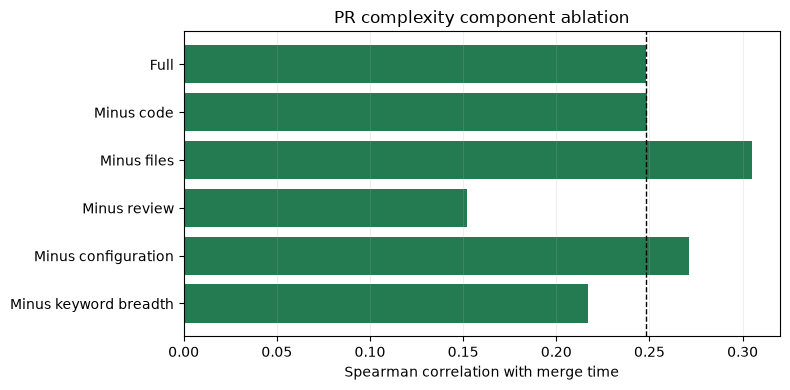

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(results["variant"], results["merge_time_rho"], color="#247a51")
ax.axvline(results.loc[0, "merge_time_rho"], color="black", linestyle="--", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Spearman correlation with merge time")
ax.set_title("PR complexity component ablation")
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ablation_merge_time.png", dpi=200)
fig.savefig(OUTPUT_DIR / "ablation_merge_time.pdf")
plt.show()


## Three paper tables
All values below are calculated from the input data. Component pairs use valid merge-time rows,
with pairwise missing-data exclusions. Association rows use the same complete comparison cohort.

Pre-review defaults to removing review burden and dividing the remaining weights by 0.75:
code 40%, files 26.667%, configuration 13.333%, keyword breadth 20%.
This may differ from the formula used for the earlier 0.350 result. To use an existing verified
pre-review score, set PRE_REVIEW_COLUMN above. The historical complexity_score is not automatically
treated as pre-review.

Pearson defaults to correlation with log1p(hours); Spearman uses raw merge time.
The caption states the transformation. Missing/constant inputs display -- rather than invented values.
Each table is printed as LaTeX and saved as CSV and .tex.

Reference the tables in the paper:
Table \ref{tab:components} reports component relationships.
Table \ref{tab:corr} compares score associations with merge time.
Table \ref{tab:ablation} reports component ablations.


In [34]:
import ast
import re
from scipy.stats import pearsonr

def finite_corr(x, y, method="spearman"):
    pair = pd.concat([x.rename("x"), y.rename("y")], axis=1)
    pair = pair.replace([np.inf, -np.inf], np.nan).dropna()
    if len(pair) < 3 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return float("nan"), len(pair)
    fn = spearmanr if method == "spearman" else pearsonr
    return float(fn(pair["x"], pair["y"]).statistic), len(pair)

def optional_numeric(column):
    if column not in df:
        return pd.Series(np.nan, index=df.index)
    return pd.to_numeric(df[column], errors="coerce").fillna(0).clip(lower=0).replace(
        [np.inf, -np.inf], np.nan)

def count_languages(value):
    if isinstance(value, (list, tuple, set)):
        return len(value)
    if not isinstance(value, str) or not value.strip():
        return np.nan
    text = value.strip()
    for parse in (json.loads, ast.literal_eval):
        try:
            parsed = parse(text)
            if isinstance(parsed, (list, tuple, set)):
                return len(parsed)
        except (ValueError, SyntaxError, TypeError):
            pass
    if not any(ch in text for ch in "[]{}"):
        return len({s.strip() for s in re.split(r"[,;]", text) if s.strip()})
    return np.nan

if "language_count" in df:
    language_count = pd.to_numeric(df["language_count"], errors="coerce")
elif "num_languages" in df:
    language_count = pd.to_numeric(df["num_languages"], errors="coerce")
elif "languages_list" in df:
    language_count = df["languages_list"].map(count_languages)
else:
    language_count = pd.Series(np.nan, index=df.index)
language_count = language_count.where(language_count.ge(0))
comments = (pd.to_numeric(df["complexity_review_comments"], errors="coerce")
            if "complexity_review_comments" in df else optional_numeric("num_review_comments"))
reviewers = (pd.to_numeric(df["complexity_reviewers"], errors="coerce")
             if "complexity_reviewers" in df else optional_numeric("num_reviewers"))
specs = [
    ("Code, files", components["code"], components["files"], "code change and file breadth"),
    ("Files, languages", components["files"], language_count, "file and language breadth"),
    ("Comments, reviewers", comments, reviewers, "discussion and participation"),
    ("Code, comments", components["code"], comments, "code change and discussion"),
    ("Code, configuration", components["code"], components["configuration"], "code and configuration change"),
]
pair_rows = []
for label, x, y, meaning in specs:
    value, count = finite_corr(x.loc[valid], y.loc[valid])
    direction = "Positive" if value > 0 else "Negative" if value < 0 else "No monotonic"
    interpretation = (f"{direction} association: {meaning}" if np.isfinite(value)
                      else "Unavailable or constant input")
    pair_rows.append({"Component pair":label, "rho":value, "Interpretation":interpretation, "n":count})
component_pairs = pd.DataFrame(pair_rows)
display(component_pairs)

if PRE_REVIEW_COLUMN:
    if PRE_REVIEW_COLUMN not in df:
        raise ValueError(f"Missing configured pre-review column: {PRE_REVIEW_COLUMN}")
    pre_review = pd.to_numeric(df[PRE_REVIEW_COLUMN], errors="coerce")
    pre_review_definition = f"Existing column: {PRE_REVIEW_COLUMN}"
else:
    pre_review = weighted_score(components, "review")
    pre_review_definition = "Review omitted; remaining weights divided by 0.75"
measures = {"LOC percentile":100*components["code"], "Files percentile":100*components["files"],
            "Pre-Review complexity":pre_review, "Post-Review complexity":full}
association_valid = valid.copy()
for values in measures.values():
    association_valid &= np.isfinite(values)
association_rows = []
for label, values in measures.items():
    x = values.loc[association_valid]
    y = minutes.loc[association_valid]/60
    pearson, count = finite_corr(x, np.log1p(y) if PEARSON_USE_LOG_HOURS else y, "pearson")
    spearman, _ = finite_corr(x, y)
    association_rows.append({"Measure":label, "Pearson":pearson, "Spearman":spearman, "n":count})
association_table = pd.DataFrame(association_rows)
display(association_table)
print("Pre-review definition:", pre_review_definition)


,Component pair,rho,Interpretation,n
0,"Code, files",0.573886,Positive association: code change and file bre...,1338401
1,"Files, languages",0.650242,Positive association: file and language breadth,1338401
2,"Comments, reviewers",0.582912,Positive association: discussion and participa...,1338401
3,"Code, comments",0.355098,Positive association: code change and discussion,1338401
4,"Code, configuration",-0.233154,Negative association: code and configuration c...,1338401


,Measure,Pearson,Spearman,n
0,LOC percentile,0.135146,0.154899,1338401
1,Files percentile,0.078126,0.087396,1338401
2,Pre-Review complexity,0.139390,0.152078,1338401
3,Post-Review complexity,0.237462,0.247936,1338401


Pre-review definition: Review omitted; remaining weights divided by 0.75


In [35]:
def latex_escape(value):
    mapping = {"&":r"\&", "%":r"\%", "$":r"\$", "#":r"\#", "_":r"\_",
               "{":r"\{", "}":r"\}", "~":r"\textasciitilde{}", "^":r"\textasciicircum{}",
               "\\":r"\textbackslash{}"}
    return "".join(mapping.get(c,c) for c in str(value))

def paper_latex(frame, caption, label, fmt, headers, subsection=False):
    lines = [r"\begin{table}[!h]", r"\caption{"+caption+r"}\label{"+label+"}",
             r"\centering\small", r"\begin{tabular}{"+fmt+"}", r"\toprule",
             " & ".join(headers)+r" \\", r"\midrule"]
    for row in frame.itertuples(index=False, name=None):
        cells = []
        for val in row:
            if isinstance(val, (float, np.floating)):
                cells.append(f"{val:.3f}" if np.isfinite(val) else "--")
            else:
                cells.append(latex_escape(val))
        lines.append(" & ".join(cells)+r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    text = "\n".join(lines)+"\n"
    return (r"\subsection{Component Ablation Analysis}"+"\n\n"+text) if subsection else text

component_tex = paper_latex(
    component_pairs[["Component pair","rho","Interpretation"]],
    "Selected Spearman correlations among score components.", "tab:components",
    r"lrp{0.38\columnwidth}", ["Component pair", r"$\rho$", "Interpretation"])
pearson_note = "Pearson uses log1p(hours)" if PEARSON_USE_LOG_HOURS else "Pearson uses raw hours"
association_tex = paper_latex(
    association_table[["Measure","Pearson","Spearman"]],
    "PR complexity score associations with merge time. "+pearson_note+"; Spearman uses raw merge time.",
    "tab:corr", "lrr", ["Measure","Pearson","Spearman"])
ablation_tex = paper_latex(
    results[["variant","merge_time_rho","rank_agreement"]],
    "Component ablation results for the post-review complexity score.", "tab:ablation",
    "lrr", ["Variant",r"Merge-time $\rho$","Rank agreement"], subsection=True)
for name, tex in [("component_correlations",component_tex),
                  ("score_merge_time_correlations",association_tex),("ablation_table",ablation_tex)]:
    (OUTPUT_DIR/f"{name}.tex").write_text(tex,encoding="utf-8")
    print(f"\n% {name}.tex\n{tex}")
component_pairs.to_csv(OUTPUT_DIR/"component_correlations.csv",index=False)
association_table.to_csv(OUTPUT_DIR/"score_merge_time_correlations.csv",index=False)
manifest.update({"pre_review_definition":pre_review_definition,
                 "association_rows":int(association_valid.sum()),
                 "pearson_target":"log1p(hours)" if PEARSON_USE_LOG_HOURS else "hours",
                 "component_pair_cohort":"valid merge-time rows, pairwise available inputs"})
(OUTPUT_DIR/"ablation_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")



% component_correlations.tex
\begin{table}[!h]
\caption{Selected Spearman correlations among score components.}\label{tab:components}
\centering\small
\begin{tabular}{lrp{0.38\columnwidth}}
\toprule
Component pair & $\rho$ & Interpretation \\
\midrule
Code, files & 0.574 & Positive association: code change and file breadth \\
Files, languages & 0.650 & Positive association: file and language breadth \\
Comments, reviewers & 0.583 & Positive association: discussion and participation \\
Code, comments & 0.355 & Positive association: code change and discussion \\
Code, configuration & -0.233 & Negative association: code and configuration change \\
\bottomrule
\end{tabular}
\end{table}


% score_merge_time_correlations.tex
\begin{table}[!h]
\caption{PR complexity score associations with merge time. Pearson uses log1p(hours); Spearman uses raw merge time.}\label{tab:corr}
\centering\small
\begin{tabular}{lrr}
\toprule
Measure & Pearson & Spearman \\
\midrule
LOC percentile & 0.135 & 0.155 

1345

## One low, medium, and high PR for comparison
Choose observed PRs nearest the 12.5th, 50th, and 87.5th post-review score percentiles.
Low is the bottom quartile, medium the middle half, and high the top quartile.
Selection uses the valid comparison cohort. Ties may leave a band empty; report this instead of
relabeling a PR. These are illustrative cases, not evidence of general performance.

Compare pre-review, post-review, and the historical complexity_score when available, along with
raw inputs, merge time, percentile shifts, and each component's weighted point contribution.
The historical score is not assumed to be the pre-review score.
The exported example CSV can contain titles and PR/repository identifiers. Review it before sharing.


In [36]:
cases = df.loc[association_valid].copy()
cases["post_review_score"] = full.loc[association_valid]
cases["pre_review_score"] = pre_review.loc[association_valid]
cases["post_review_percentile"] = cases["post_review_score"].rank(pct=True)*100
cases["pre_review_percentile"] = cases["pre_review_score"].rank(pct=True)*100
cases["post_minus_pre_percentile"] = cases["post_review_percentile"]-cases["pre_review_percentile"]
cases["hours_to_merge"] = minutes.loc[association_valid]/60
if "complexity_score" in cases:
    cases["historical_percentile"] = pd.to_numeric(cases["complexity_score"],errors="coerce").rank(pct=True)*100
    cases["post_minus_historical_percentile"] = cases["post_review_percentile"]-cases["historical_percentile"]
for key, weight in WEIGHTS.items():
    cases[f"{key}_percentile"] = components.loc[cases.index,key]*100
    cases[f"{key}_points"] = components.loc[cases.index,key]*weight*100
selected=[]
for level,center,lower,upper in [("Low",9,0,25),("Medium",51,25,75),("High",88,75,100)]:
    mask=cases["post_review_percentile"].le(upper)
    mask &= cases["post_review_percentile"].ge(lower) if lower==0 else cases["post_review_percentile"].gt(lower)
    pool=cases.loc[mask]
    if pool.empty:
        warnings.warn(f"No {level} example: percentile band is empty due to ties or sample size.")
        continue
    idx=(pool["post_review_percentile"]-center).abs().idxmin()
    row=pool.loc[[idx]].copy()
    row.insert(0,"example_level",level)
    row["largest_component_contribution"]=row[[f"{k}_points" for k in WEIGHTS]].idxmax(axis=1).str.replace("_points","",regex=False)
    selected.append(row)
if not selected:
    raise ValueError("No examples available.")
examples=pd.concat(selected)
first=["example_level","pull_request_id","combined_text_nlp","complexity_score",
       "pre_review_score","post_review_score","pre_review_percentile","post_review_percentile",
       "post_minus_pre_percentile","historical_percentile","post_minus_historical_percentile",
       "hours_to_merge","largest_component_contribution","code_lines_modified","lines_modified",
       "files_touched","num_review_comments","num_reviewers","config_lines_modified",
       "keyword_category_count","keyword_categories","languages_list"]
cols=[c for c in first if c in examples]
cols += [f"{k}_percentile" for k in WEIGHTS]+[f"{k}_points" for k in WEIGHTS]
examples=examples[cols].reset_index(drop=True)
display(examples)
display(examples.set_index("example_level").T)
print("Component points sum to the unrounded post-review score.")
if EXPORT_EXAMPLES:
    examples.to_csv(OUTPUT_DIR/"representative_pr_examples.csv",index=False)
    print("Saved", OUTPUT_DIR/"representative_pr_examples.csv")


,example_level,pull_request_id,combined_text_nlp,complexity_score,pre_review_score,post_review_score,pre_review_percentile,post_review_percentile,post_minus_pre_percentile,historical_percentile,...,code_percentile,files_percentile,review_percentile,configuration_percentile,categories_percentile,code_points,files_points,review_points,configuration_points,categories_points
0,Low,3344564615,debugeventwaiter conditionalbreakpointswithfil...,18.0,26.65,31.29,6.446498,9.003991,2.557492,17.194510,...,49.078340,14.796126,45.231265,17.020572,4.005414,14.723502,2.959225,11.307816,1.702057,0.600812
1,Medium,3450429408,version codexu.notegen version automated spect...,55.0,43.65,46.93,43.109502,50.992154,7.882653,50.429318,...,20.156814,77.521012,56.770617,87.664796,16.151549,6.047044,15.504202,14.192654,8.766480,2.422732
2,High,3446001495,cypress migration playwright cypress been move...,97.0,79.66,71.05,92.384457,88.000046,-4.384411,96.890805,...,89.168605,96.203006,45.231265,89.189002,32.241682,26.750581,19.240601,11.307816,8.918900,4.836252


example_level,Low,Medium,High
pull_request_id,3344564615,3450429408,3446001495
combined_text_nlp,debugeventwaiter conditionalbreakpointswithfil...,version codexu.notegen version automated spect...,cypress migration playwright cypress been move...
complexity_score,18.0,55.0,97.0
pre_review_score,26.65,43.65,79.66
post_review_score,31.29,46.93,71.05
pre_review_percentile,6.446498,43.109502,92.384457
post_review_percentile,9.003991,50.992154,88.000046
post_minus_pre_percentile,2.557492,7.882653,-4.384411
historical_percentile,17.19451,50.429318,96.890805
post_minus_historical_percentile,-8.19052,0.562836,-8.890758


Component points sum to the unrounded post-review score.
Saved ..\results\ablation\representative_pr_examples.csv


In [37]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.width", None,
):
    display(pd.read_csv(OUTPUT_DIR / "representative_pr_examples.csv"))

,example_level,pull_request_id,combined_text_nlp,complexity_score,pre_review_score,post_review_score,pre_review_percentile,post_review_percentile,post_minus_pre_percentile,historical_percentile,post_minus_historical_percentile,hours_to_merge,largest_component_contribution,code_lines_modified,lines_modified,files_touched,num_review_comments,num_reviewers,config_lines_modified,keyword_category_count,keyword_categories,languages_list,code_percentile,files_percentile,review_percentile,configuration_percentile,categories_percentile,code_points,files_points,review_points,configuration_points,categories_points
0,Low,3344564615,debugeventwaiter conditionalbreakpointswithfileclass see,18.0,26.65,31.29,6.446498,9.003991,2.557492,17.194510,-8.190520,4.533333,code,5,5,1,0,1,0,0,[],['Java'],49.078340,14.796126,45.231265,17.020572,4.005414,14.723502,2.959225,11.307816,1.702057,0.600812
1,Medium,3450429408,version codexu.notegen version automated spectershell dumplings workflow run microsoft reviewers open codeflow,55.0,43.65,46.93,43.109502,50.992154,7.882653,50.429318,0.562836,1.633333,files,0,158,8,0,2,158,1,"[""dependency""]",['YAML'],20.156814,77.521012,56.770617,87.664796,16.151549,6.047044,15.504202,14.192654,8.766480,2.422732
2,High,3446001495,cypress migration playwright cypress been moved deprecated folder now playwright dependencies now installed playwright login wiremock migrated updating playwright dev runs,97.0,79.66,71.05,92.384457,88.000046,-4.384411,96.890805,-8.890758,18.000000,code,540,737,47,0,1,197,2,"[""testing"", ""dependency""]","['Ignore List', 'JSON', 'JSON with Comments', 'JavaScript', 'TypeScript', 'YAML']",89.168605,96.203006,45.231265,89.189002,32.241682,26.750581,19.240601,11.307816,8.918900,4.836252
